# Movement during quiescence → reaction time, in both datasets

Does more movement during the final quiescence period (wheel held still) go with a longer RT? This is checked in the NM sessions and in the BWM sessions of the individuality paper, with the same per-trial measures:
- **Movement**, over the final quiescence: mean log(1 + whisker ME), log(1 + left-paw speed), log(1 + |wheel velocity|), and licks.
- **RT**: first movement − stimulus/go cue, log, RT > 50 ms.
- **Model**: per session, OLS with |contrast| level, previous outcome and trial position (+ squared) held fixed. Each signal alone, and all four jointly. Standardised β = SD change in log RT per SD of movement. Mice are the unit.

Functions: `Functions/quiescence_rt.py`. BWM uses all 332 sessions in `data/states_files` (101 mice), not only the LDA subset.

In [1]:
import sys, pathlib, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
REPO = pathlib.Path.cwd().resolve()
while not (REPO / 'Functions' / 'quiescence_rt.py').exists() and REPO != REPO.parent:
    REPO = REPO.parent
sys.path.insert(0, str(REPO))
from Functions import quiescence_rt as qr
warnings.filterwarnings('ignore')

B = {'NM': qr.betas(qr.nm_table()), 'BWM': qr.betas(qr.bwm_table())}
pd.concat({k: qr.across_mice(b) for k, b in B.items()}, axis=1)

NM                          BWM                   
                  mean β positive         p    mean β positive         p
joint whisking  0.110796    31/36  0.000001  0.038391   65/101  0.001224
joint paw       0.032649    25/36  0.004802  0.073434    79/96       0.0
joint wheel    -0.021597     8/36  0.002442 -0.022548   35/101  0.000958
joint lick     -0.024494     6/36  0.000041  0.019915   53/100  0.007043
alone whisking  0.116218    33/36       0.0  0.092624   87/101       0.0
alone paw       0.095204    36/36       0.0  0.100511    86/96       0.0
alone wheel     0.052567    34/36       0.0  0.030282   74/101  0.000037
alone lick      0.004024    21/36  0.341534  0.054094   76/100       0.0

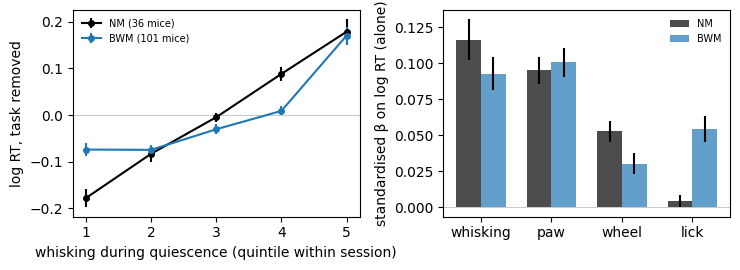

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(7.5, 2.8))
ax = axes[0]
for name, c in [('NM', 'k'), ('BWM', 'C0')]:
    Q = np.stack(B[name].groupby('subject')['whisking quintile RT'].apply(lambda s: np.mean(np.stack(s), 0)))
    ax.errorbar(np.arange(1, 6), Q.mean(0), Q.std(0) / np.sqrt(len(Q)), color=c, marker='o', ms=4,
                label=f'{name} ({len(Q)} mice)')
ax.axhline(0, c='0.7', lw=0.5)
ax.set(xlabel='whisking during quiescence (quintile within session)', ylabel='log RT, task removed', xticks=range(1, 6))
ax.legend(frameon=False, fontsize=7)
ax = axes[1]
w = 0.35
for k, (name, c) in enumerate([('NM', 'k'), ('BWM', 'C0')]):
    M = B[name].groupby('subject')[[f'alone {s}' for s in qr.SIGNALS]].mean()
    ax.bar(np.arange(4) + (k - 0.5) * w, M.mean(), w, yerr=M.sem(), color=c, alpha=0.7, label=name)
ax.axhline(0, c='0.7', lw=0.5)
ax.set_xticks(range(4), qr.SIGNALS); ax.set_ylabel('standardised β on log RT (alone)')
ax.legend(frameon=False, fontsize=7)
fig.tight_layout()

**Reading.** Yes, in both datasets more movement during quiescence goes with a longer RT.
- **Each signal alone:** whisking and paw give β ≈ +0.1 SD in both (NM 33/36 and 36/36 mice; BWM 87/101 and 86/96). Wheel and licking are weaker.
- **Size:** in the NM sessions, RT rises steadily across whisking quintiles; the top quintile is ~43% slower than the bottom (Δ log RT ≈ 0.36). In BWM the effect is concentrated in the top quintile (~27% slower than the bottom).
- **Jointly, the datasets weight the signals differently.** Whisking carries most of it in NM (β 0.11 vs paw 0.03). Paw carries most of it in BWM (0.07 vs whisking 0.04). Paw and whisking are correlated, and BWM has both cameras' tracking, so which one "wins" is not meaningful. The robust statement is *movement during quiescence → slower*.
- **Wheel jointly is slightly negative** in both. That is what is left once paw and whisking are in; wheel is ~0 by design during quiescence.
- **Overall:** the per-trial effect is small (β ~0.1, i.e. ~1% of RT variance per signal). It is consistent across mice and replicates across the two datasets.

## Isn't whisking a sign of engagement (LD1)?

The relation depends on the level of comparison and on the epoch. BWM, whisking measured as the fraction of time in the whisking syllable (the measure behind the syllable features), Spearman r with log RT at three levels:
- **between mice**: mouse means;
- **sessions within mouse**: mice with ≥ 3 sessions;
- **trials within session**: mean over a mouse's sessions.

In [3]:
W = qr.bwm_whisk_epochs()
cols = ['pre-quiescence', 'quiescence', 'stimulus', 'choice', 'ITI', 'whole trial', 'licking, whole trial']
qr.levels(W, cols).round(3)

,between mice,p (mice),sessions within mouse,p (sessions),trials within session,p (trials)
whisking during,,,,,,
pre-quiescence,-0.248,0.012,-0.207,0.011,-0.015,0.166
quiescence,-0.223,0.025,0.031,0.704,-0.013,0.394
stimulus,-0.463,0.000,-0.205,0.012,-0.224,0.000
choice,-0.248,0.012,-0.319,0.000,-0.075,0.000
ITI,0.003,0.974,0.005,0.954,-0.084,0.000
whole trial,-0.510,0.000,-0.470,0.000,-0.369,0.000
"licking, whole trial",-0.276,0.005,-0.359,0.000,-0.334,0.000


**Reading.**
- **Between mice, and across a mouse's sessions, more whisking goes with faster responses.** Over the whole trial: r = −0.51 between mice, −0.47 across sessions. This is the LD1 / engagement picture: a mouse, or a day, with a lot of whisking is a fast one. It holds for whisking during quiescence too, between mice (r = −0.22).
- **Within a session, trial to trial, whisking *time* during quiescence says nothing about RT** (r = −0.01). The slowing in the analysis above comes from the continuous whisker *motion energy* (and paw speed): how vigorously the face and body move while the mouse should be still, not whether it is in the whisking state. That looks like fidgeting rather than engaged whisking.
- **Whole-trial and stimulus-epoch whisking correlate with faster RT within a session too** (r = −0.37 and −0.22). This is partly mechanical: on a slow trial the stimulus epoch is long, and the trial's composition shifts towards epochs with less whisking.

So the two results are not in conflict. Whisking as a trait (more whisking mice, more whisking days) goes with fast, engaged behaviour. Extra movement energy during the quiescence of a given trial goes with a slightly slower response on that trial.